**Выполнил:** Мертехин Михаил Дмитриевич, группа U3275 (ВизМод 3.1)

# Постановка задачи


**Цель работы:** исследование и обработка данных для повышения их качества.

**Краткое описание:** в лабораторной работе приводится поэтапный план изучения и обработки намеренно не предобработанных данных. Необходимо выполнить все этапы плана и оценить результаты преобразований.

# Данные



В папке [Data/lab3](https://drive.google.com/drive/folders/1437z7m5Ut4WUJOhJg1oZz13dtBpxgFKs?usp=share_link) расположена таблица `monster_com_job_sample.com` с данными о вакансиях. Также эти данные с описанием и примерами обработки можно найти на [kaggle](https://www.kaggle.com/code/ankkur13/perfect-dataset-to-get-the-hands-dirty/data#).

##### **Формат данных**

```
country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
United States of America,US,"",No,jobs.monster.com,"TeamSoft is seeing an IT Support Specialist to join our client in Madison, WI. The ideal candidate must have at least 6 years of experience in the field. They need to be familiar with a variety of the field's concepts, practices, and procedures as this position relies on extensive experience and judgment to plan and accomplish goals. Required Skills:вАҐ Call tracking softwareвАҐ Phone based technical supportвАҐ Problem documentation and communicationвАҐ Remote Desktop Management ToolsвАҐ Respond to customer requestsвАҐ General understanding of LANDeskвАҐ Microsoft Office 2007 SuiteFind out why TeamSoft is the Madison area's technology leader with over 200 IT consultants. Owned, operated, and managed by IT consultants, TeamSoft is the clear choice for your career. Join the TeamSoft family today!Did you know?вАҐ TeamSoft offers salaried options for many positions that include 5 weeks PTO and great benefits!вАҐ TeamSoft has been in business since 1996вАҐ TeamSoft's owners are local IT professionals who possess a wealth of experience in application development, business analysis, and project managementвАҐ TeamSoft's Recruiters are knowledgeable, friendly, and ready to help you make your next great career moveвАҐ TeamSoft offers a full benefits suite to all of our W2 consultants, including a 401k plan with a 100% vested 4% dollar for dollar matchвАҐ Our targeted selection process is designed to get to know your strengths and career interests and provide you with the best chance for success in your new positionвАҐ Our longest running consultant has been with us for 16 yearsвАҐ Consultants can participate in our charitable giving committee. To date, TeamSoft's charitable giving committee has donated over $100,000!TeamSoft is owned by local IT professionals. Our team also has deep experience with IT staffing. Our clients understand this and rely on our expertise. That is why TeamSoft is the Madison Area's largest privately owned IT consulting firm, with more than 200 current consultants! With over 50 active clients, TeamSoft will give you the greatest exposure to the widest range of IT careers.Our owners possess a combined 60+ years of IT consulting experience. Our recruiting and Account Management staff are very well-versed in our client markets. We get you. We know you. We know what you do every day. And we know what you deal with on the job.You take your career seriously and so do we. At TeamSoft you are not just a resume or number. Our goal is to create long-term partnerships with each of our consultants, and according to feedback from many of them, we are very good at this. Click HERE to see what our consultants have to say about working with TeamSoft.TeamSoft -- Promote yourself!TeamSoft is an equal employment opportunity employer functioning under an Affirmative Action Plan.",IT Support Technician Job in Madison,Full Time Employee,"Madison, WI 53702","",http://jobview.monster.com/it-support-technician-job-madison-wi-us-167855963.aspx?mescoid=1500134001001&jobPosition=20,"",IT/Software Development,11d599f229a80023d2f40e7c52cd941e
United States of America,US,"",No,jobs.monster.com,"The Wisconsin State Journal is seeking a flexible and motivated reporter/editor to lead its three-person business desk. WeвАЩre looking for an experienced journalist able to spot trends, be a watchdog and reflect the Madison areaвАЩs vibrant entrepreneurial community. This is a hybrid reporting and editing position that calls for a fleet-footed, multimedia storyteller able to maximize the newspaperвАЩs online presentation while also editing two sections a week. Candidates must have strong news judgment, be well versed in business news and trends and be able to quickly prioritize coverage.At least five yearsвАЩ experience reporting or editing for digital and print platforms desired. To be considered for the position, applicants must apply online.¬†As part of your online application, please attach five samples of your work or links to five recent stories.Wisconsin State Journal, 1901 Fish Hatchery Road, Madison, WI 53713Affirmative Action/Equal Opportunity Employer/Pre-employment drug testing appliesPI94338362Apply Here",Business Reporter/Editor Job in Madison,Full Time,"Madison, WI 53708",Printing and Publishing,http://jobview.monster.com/business-reporter-editor-job-madison-wi-us-167830105.aspx?mescoid=2700437001001&jobPosition=7,"","",e4cbb126dabf22159aff90223243ff2a
...
```

##### **Описание полей**
 - ```country``` — наименование страны;
 - ```country_code``` — код страны;
 - ```date_added``` — дата размещения вакансии;
 - ```has_expired``` — актуальность вакансии;
 - ```job_board``` — агрегатор вакансий, с которого собраны данные;
 - ```job_description``` — описание вакансии;
 - ```job_title``` — наименование должности;
 - ```job_type``` — вид занятости;
 - ```location``` — метоположение организации;
 - ```organization``` — наименование организации;
 - ```page_url``` — ссылка на страницу с вакансией;
 - ```salary``` — заработная плата;
 - ```sector``` — сфера деятельности;
 - ```uniq_id``` — уникальный идентификатор записи о вакансии.

# Понимание данных

In [1]:
import re
import numpy as np
import pandas as pd
import missingno as msno
from matplotlib import pyplot as plt
import seaborn as sns
from IPython.display import display

plt.rcParams['figure.dpi'] = 100


В датасете есть несколько столбцов, в каждой ячейке которых записано одно и то же значение. Есть столбцы, в которых формат записи значений не стандартизирован. А есть такие, где указана информация, не соответствующая названию столбца.

**Первый этап изучения данных** – понять, какие основные проблемы предстоит решить для каждого из столбцов. Для этого загрузите датасет и выведите случайные несколько строк из него. Постарайтесь понять, что из себя представляют данные в столбцах.

In [2]:
# Загрузка данных: локально из папки data/, иначе (например, в Colab) — с Google Drive
from pathlib import Path

DATA_URL = "https://drive.usercontent.google.com/download?id=1s_X49sgW_HQQALThvElR8g4_Mp-VaWEo&export=download&confirm=t"
local = Path("data/monster_com_job_sample.csv")
df = pd.read_csv(local if local.exists() else DATA_URL)

pd.set_option("display.max_colwidth", 80)
print(df.shape)
df.sample(5, random_state=42)

(22000, 14)


,country,country_code,date_added,has_expired,job_board,job_description,job_title,job_type,location,organization,page_url,salary,sector,uniq_id
13035,United States of America,US,NaN,No,jobs.monster.com,The QC Lead position requires an understanding of food science and food/diet...,Quality Control Lead Job in Santa Cruz,Full Time,"Santa Cruz, CA 95060",Manufacturing - Other,http://jobview.monster.com/Quality-Control-Lead-Job-Santa-Cruz-CA-US-1643703...,NaN,Experienced (Non-Manager),c44af81ceb38d2b6fe00baf15d0dffe6
3115,United States of America,US,NaN,No,jobs.monster.com,JOB DESCRIPTION DEPARTMENT: ...,Case Manager Job in Sunset Point,Full Time Employee,"Sunset Point, FL 33765",Healthcare Services,http://jobview.monster.com/Case-Manager-Job-Sunset-Point-FL-US-166104158.asp...,NaN,Medical/Health,217600308ffc96a1a81eb8afba5ee522
8732,United States of America,US,NaN,No,jobs.monster.com,POSITION PURPOSE The Senior Manager Foundation PR will be responsible for dr...,Sr Manager,Full Time,"Atlanta, GA 30301",Retail,http://jobview.monster.com/sr-manager-foundation-pr-job-atlanta-ga-us-170527...,NaN,Manager (Manager/Supervisor of Staff),ef7db9ba10dd8bf7754ecf6ddd09a5aa
7591,United States of America,US,NaN,No,jobs.monster.com,GroundskeeperWest Knox Apart need a F/T Groundskeeper. Duties - clean breeze...,Groundskeeper Job in Knoxville,Full Time,"Knoxville, TN 37923",NaN,http://jobview.monster.com/Groundskeeper-Job-Knoxville-TN-US-166981535.aspx?...,NaN,NaN,cd3adb94fc647ca5ea3af731dc1da065
221,United States of America,US,NaN,No,jobs.monster.com,"Combined Insurance is seeking Sales Agents to join our fast-paced, high ener...",Sales Agent Job in Knoxville,Full Time,"Knoxville, TN",Insurance,http://jobview.monster.com/Sales-Agent-Job-Knoxville-TN-US-166279908.aspx?me...,NaN,NaN,ec59e3f419b851259632b757183d7365


In [3]:
# Типы данных и примеры значений — для заполнения таблицы ниже
pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "уникальных": df.nunique(),
    "пример": df.apply(lambda c: str(c.dropna().iloc[0])[:60]),
})

,dtype,уникальных,пример
country,object,1,United States of America
country_code,object,1,US
date_added,object,78,5/10/2016
has_expired,object,1,No
job_board,object,1,jobs.monster.com
job_description,object,18744,TeamSoft is seeing an IT Support Specialist to join our clie
job_title,object,18759,IT Support Technician Job in Madison
job_type,object,39,Full Time Employee
location,object,8423,"Madison, WI 53702"
organization,object,738,Printing and Publishing


**Задание**

Составьте таблицу, в которой будет содержаться название столбца, тип данных в нем и краткое описание проблем, которые вы заметили при первом взгляде на данные.

Название столбца | Тип данных | Проблемы
--- | --- | ---
```country``` | object (строка) | Во всех 22 000 строках одно значение `United States of America` — столбец не несёт информации
```country_code``` | object (строка) | Одно значение `US` во всех строках, дублирует `country`
```date_added``` | object (должна быть дата) | Заполнено только 122 строки из 22 000; хранится строкой `M/D/YYYY`, а не датой
```has_expired``` | object (по смыслу bool) | Везде `No` — неинформативен; по смыслу логический тип
```job_board``` | object (строка) | Везде `jobs.monster.com` — неинформативен
```job_description``` | object (текст) | Длинный текст, «битая» кодировка (`вАҐ` вместо `•`); часть описаний попала в другие столбцы
```job_title``` | object (строка) | К должности дописан город (`... Job in Madison`); иногда вместо должности — текст описания
```job_type``` | object (категория) | Один и тот же тип записан по-разному (`Full Time, Employee` / `Full Time Employee` / `Full Time / Employee`), лишние пробелы, префикс `Job Type`; 1 628 пропусков
```location``` | object (строка) | Смесь форматов: город + штат + индекс в разных комбинациях; встречаются контакты, телефоны и текст вакансии
```organization``` | object (строка) | 6 867 пропусков; часто вместо названия компании — отрасль (`Healthcare Services`, `Retail`)
```page_url``` | object (строка) | Уникален в каждой строке; содержит должность, город и id — частично дублирует другие поля
```salary``` | object (должны быть числа) | 18 554 пропуска; разные форматы (диапазон, «от», «до»), период то указан, то нет, есть произвольный текст
```sector``` | object (категория) | 5 194 пропуска; часто вместо сферы — уровень должности (`Experienced (Non-Manager)`, `Entry Level`), иногда название компании
```uniq_id``` | object (строка, hash) | Проблем не видно — нужно проверить уникальность

### Оценка пустых ячеек в датасете

Выясните, в каких столбцах, строках и в каком количестве отсутствуют данные:
1. С помощью модуля `pandas` составьте таблицу, где каждому названию столбца будет сопоставлено общее количество ячеек и количество пустых ячеек.
2. Подсчитайте количество строк датасета, в которых пустыми являются более 75% ячеек.
3. Визуализируйте число пропусков в датасете с помощью модуля, построив столбчатую диаграмму. Для удобства можно воспользоваться модулем `missingno`.


,всего ячеек,пустых,"доля пустых, %"
date_added,22000,21878,99.4
salary,22000,18554,84.3
organization,22000,6867,31.2
sector,22000,5194,23.6
job_type,22000,1628,7.4
country,22000,0,0.0
country_code,22000,0,0.0
has_expired,22000,0,0.0
job_board,22000,0,0.0
job_description,22000,0,0.0


Строк, где пусто > 75% ячеек: 0
Максимальная доля пустых ячеек в строке: 0.357


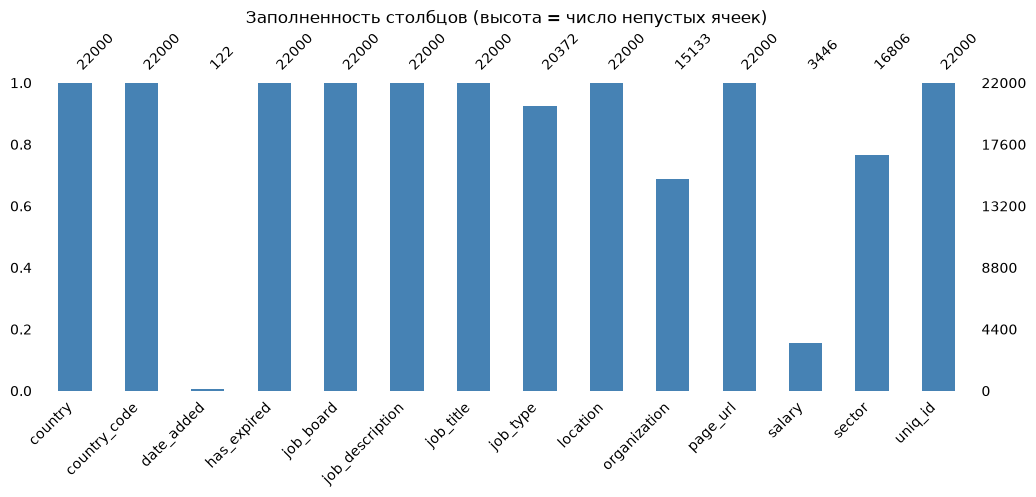

In [4]:
# 1. Общее количество ячеек и количество пустых по каждому столбцу
missing = pd.DataFrame({
    "всего ячеек": df.shape[0],
    "пустых": df.isna().sum(),
})
missing["доля пустых, %"] = (missing["пустых"] / missing["всего ячеек"] * 100).round(1)
display(missing.sort_values("пустых", ascending=False))

# 2. Строки, в которых пусто более 75% ячеек
row_share = df.isna().mean(axis=1)
print("Строк, где пусто > 75% ячеек:", (row_share > 0.75).sum())
print("Максимальная доля пустых ячеек в строке:", round(row_share.max(), 3))

# 3. Визуализация пропусков
msno.bar(df, figsize=(12, 4), fontsize=10, color="steelblue")
plt.title("Заполненность столбцов (высота = число непустых ячеек)")
plt.show()

**Выводы.** Пропуски сосредоточены в пяти столбцах: `date_added` (99,4 %), `salary` (84,3 %), `organization` (31,2 %), `sector` (23,6 %) и `job_type` (7,4 %). Остальные столбцы заполнены полностью. Строк, где пусто более 75 % ячеек, нет: даже в самой «пустой» строке не хватает только 5 из 14 значений (≈ 36 %).

Проверьте, как изменится размер датасета, если принять решение удалить все строки, где есть пустые значения. Сделайте выводы.

In [5]:
before = len(df)
after = len(df.dropna())
print(f"До удаления: {before} строк, после dropna(): {after} строк "
      f"(осталось {after / before:.3%})")

# Если не учитывать почти пустой date_added
after_wo_date = len(df.drop(columns="date_added").dropna())
print(f"Без учёта date_added: осталось бы {after_wo_date} строк ({after_wo_date / before:.1%})")

До удаления: 22000 строк, после dropna(): 5 строк (осталось 0.023%)
Без учёта date_added: осталось бы 1919 строк (8.7%)


**Выводы.** Если удалить все строки с пропусками, из 22 000 записей останется 5 — данные станут бесполезны. Главная причина — `date_added` (заполнен лишь в 0,6 % строк): даже без него осталось бы только 1 919 строк (8,7 %), потому что `salary` заполнен в 15,7 % строк. Поэтому пропуски нельзя удалять «оптом»: почти пустые столбцы лучше исключить из анализа, а остальные пропуски обрабатывать в зависимости от задачи (заполнять, оставлять как «нет данных», фильтровать только для конкретного расчёта).

### Первичная оценка данных в столбцах

Изучите данные в столбцах датасета, ответив на следующие вопросы:
1. Есть ли столбцы, в которых встречается всего одно значение? Как их можно использовать в анализе?
2. Есть ли такие значения, которые встречаются более чем в одном столбце?
3. Есть ли столбцы, данные в которых не соответствуют названию столбца?

In [6]:
# 1. Столбцы с единственным значением
nunique = df.nunique(dropna=False)
print("Столбцы с одним значением:")
for col in nunique[nunique == 1].index:
    print(f"  {col}: {df[col].iloc[0]!r}")

# 2. Значения, встречающиеся более чем в одном столбце
text_cols = ["job_title", "job_type", "location", "organization", "salary", "sector"]
values = {c: set(df[c].dropna().str.strip()) for c in text_cols}
print("\nОбщие значения в парах столбцов:")
for i, a in enumerate(text_cols):
    for b in text_cols[i + 1:]:
        common = values[a] & values[b]
        if common:
            print(f"  {a} ∩ {b}: {len(common)} шт., например {sorted(common)[:3]}")

# Текст описания вакансии внутри других столбцов
desc = set(df["job_description"].str.strip())
print("\nСколько ячеек совпадает с каким-либо job_description или длиннее 200 символов:")
for c in text_cols:
    s = df[c].dropna().str.strip()
    print(f"  {c}: {(s.isin(desc) | (s.str.len() > 200)).sum()}")

# 3. Данные, не соответствующие названию столбца
print("\norganization — самые частые значения (это отрасли, а не компании):")
display(df["organization"].value_counts().head(8))
print("sector — самые частые значения (это уровень должности, а не сфера):")
display(df["sector"].value_counts().head(8))
print("location — примеры значений, не являющихся местоположением:")
display(df.loc[df["location"].str.contains("Contact name|Phone|Position", na=False), "location"].head(5))

Столбцы с одним значением:
  country: 'United States of America'
  country_code: 'US'
  has_expired: 'No'
  job_board: 'jobs.monster.com'

Общие значения в парах столбцов:
  job_title ∩ location: 12 шт., например ['Business Analyst', 'Field Service Technician', 'Job Details']
  job_type ∩ location: 1 шт., например ['Full Time Employee']
  job_type ∩ organization: 1 шт., например ['Full Time Employee']
  location ∩ organization: 126 шт., например ['A & E Network', 'Albany, NY', 'Allentown, PA']
  organization ∩ sector: 2 шт., например ['Electrical/Electronics EngineeringIndustrial/Manufacturing EngineeringMechanical Engineering', 'Retail']

Сколько ячеек совпадает с каким-либо job_description или длиннее 200 символов:
  job_title: 39
  job_type: 0
  location: 1224
  organization: 0
  salary: 7
  sector: 8

organization — самые частые значения (это отрасли, а не компании):


organization
Healthcare Services          1919
All                          1158
Retail                       1081
Other/Not Classified         1048
Manufacturing - Other         885
Computer/IT Services          822
Legal Services                466
Business Services - Other     410
Name: count, dtype: int64

sector — самые частые значения (это уровень должности, а не сфера):


sector
Experienced (Non-Manager)                4594
Medical/Health                           1254
Entry Level                              1172
Sales/Retail/Business Development         938
Manager (Manager/Supervisor of Staff)     900
IT/Software Development                   861
Project/Program Management                790
Accounting/Finance/Insurance              742
Name: count, dtype: int64

location — примеры значений, не являющихся местоположением:


2      DePuy Synthes Companies is a member of Johnson & Johnson's Family of Compani...
6                                                              Contact name Tony Zerio
212    Job Description : Want more than just a job? Join Forever 21’s Retail Operat...
271    Work Schedule:      Daily route schedules determine the work hours and avera...
298                                                               Phone 1-800-405-5591
Name: location, dtype: object

**Выводы.**
1. В четырёх столбцах одно значение на все строки: `country`, `country_code`, `job_board`, `has_expired`. Для анализа внутри датасета они бесполезны: они лишь описывают выборку (все вакансии из США, с monster.com, актуальные). Их можно удалить или использовать как метаданные, например при объединении с другими источниками.
2. Значения переходят из столбца в столбец. У `location` и `organization` 126 общих значений: в `location` лежат названия компаний, а в `organization` — города (`Albany, NY`). В `organization` и `sector` встречаются одинаковые значения (`Retail`). В `location` 1 224 ячейки содержат текст описания вакансии. В `location`, `organization`, `sector`, `salary` и `job_title` попадаются куски `job_description`. Город указан и в `location`, и в `job_title`, и в `page_url`.
3. Содержимое не соответствует названию. В `organization` чаще всего лежит **отрасль** (`Healthcare Services`, `Retail`, `All`). В `sector` чаще всего лежит **уровень позиции** (`Experienced (Non-Manager)`, `Entry Level`, `Manager ...`). В `location` встречаются контакты, телефоны и фрагменты описания. В `salary` вместо суммы часто стоит текст про бонусы и льготы.

### Дублирование данных

Для поиска дублирующихся строк выполните следующие действия:
1. В таблице есть столбец `uniq_id`, значения которого, как сказано в описании данных, являются уникальными идентификаторами записей. Проверьте, действительно ли в этом столбце все значения различны.
2. Проверьте, есть ли в таблице другие столбцы, значения которых в каждой строке различны.
3. Если игнорировать столбцы, где все значения различны, найдутся ли такие строки, для которых значения по всем остальным столбцам будут совпадать?

Оцените результаты поиска дубликатов.

In [7]:
# 1. Уникален ли uniq_id
print("uniq_id уникален:", df["uniq_id"].is_unique, f"({df['uniq_id'].nunique()} из {len(df)})")

# 2. Другие столбцы, где все значения различны
all_unique = [c for c in df.columns if df[c].is_unique]
print("Столбцы, где все значения различны:", all_unique)

# 3. Дубликаты по остальным столбцам
rest = df.drop(columns=all_unique)
dup_mask = rest.duplicated(keep=False)
print(f"Строк, совпадающих по всем остальным столбцам: {dup_mask.sum()} "
      f"(лишних копий: {rest.duplicated().sum()})")

# Пример группы дубликатов: отличаются только uniq_id и page_url
example = df[dup_mask].sort_values(["job_title", "location"]).head(4)
display(example[["job_title", "location", "organization", "page_url", "uniq_id"]])

uniq_id уникален: True (22000 из 22000)


Столбцы, где все значения различны: ['page_url', 'uniq_id']


Строк, совпадающих по всем остальным столбцам: 2078 (лишних копий: 1168)


,job_title,location,organization,page_url,uniq_id
795,# Plano Retail Co-Manager Job in Plano,"Plano, TX 75093",Retail,http://jobview.monster.com/720-plano-retail-co-manager-job-plano-tx-us-16821...,000d6b27ca3019e5a8c36e021fd6a188
11354,# Plano Retail Co-Manager Job in Plano,"Plano, TX 75093",Retail,http://jobview.monster.com/720-plano-retail-co-manager-job-plano-tx-us-16821...,d8503658d538c95b28a0e437c7200955
3806,./hr Experienced RN supervisor (Smithtown) Job in Smithtown,"Smithtown, NY 11787",Healthcare Services,http://jobview.monster.com/40-00-hr-Experienced-RN-supervisor-Smithtown-Job-...,2c594aad12dc6ae51125bff47d6c6e9a
19461,./hr Experienced RN supervisor (Smithtown) Job in Smithtown,"Smithtown, NY 11787",Healthcare Services,http://jobview.monster.com/40-00-hr-Experienced-RN-supervisor-Smithtown-Job-...,ff48b23f28421fb290369f4d5e66237d


**Выводы.** `uniq_id` действительно уникален, и `page_url` тоже. Но оба поля технические: id — это хеш записи, а ссылка отличается параметрами (`jobPosition=...`). Если их не учитывать, 2 078 строк совпадают по всем остальным полям, то есть 1 168 строк — лишние копии (≈ 5 % датасета). Это одна и та же вакансия, собранная парсером несколько раз с разных позиций выдачи. Для анализа такие дубликаты стоит удалить (`drop_duplicates` по содержательным столбцам), иначе статистика по зарплатам, городам и типам занятости будет смещена.

# Практические задания

В этом разделе необходимо обработать значения в трех столбцах датасета: `location`, `salary` и `job_type`. Цель обработки – стандартизировать данные в каждом из столбцов так, чтобы их можно было анализировать.

### Задание 1

В задании 1 необходимо провести обработку столбца `location`.

#### Задание 1.1

В столбце `location` представлена информация о местоположении организации, в которой открыта вакансия. Каждое значение столбца `location` содержит информацию о городе, коде штата и почтовом индексе.

Однако не в каждой строке есть все три характеристики местоположения, а также могут встречаться разные комбинации из них, записанные в виде строки в произвольном порядке и с разными разделителями.

Например, может быть указан только код штата, только название города или только индекс. Могут быть указаны любые две характеристики из трех.

**Формулировка задания:**
1. Определите, какие форматы встречаются.
2. Напишите одно или несколько регулярных выражений для поиска выявленных форматов.
3. Визуализируйте количество найденных форматов на столбчатой или круговой диаграмме. Также покажите на ней количество строк, в которых формат определить не удалось. Какие форматы встречаются чаще всего?

Ознакомиться с теоретическим материалом по работе с регулярными выражениями можно [по ссылке](https://colab.research.google.com/drive/1eFHdmt9OROLEDJRNc2wNmz0gpE1O3sKU?usp=sharing).

,строк
location_format,
"город, штат индекс",11375
"город, штат",7177
не определён,2616
город индекс,327
индекс,254
штат,230
штат индекс,21


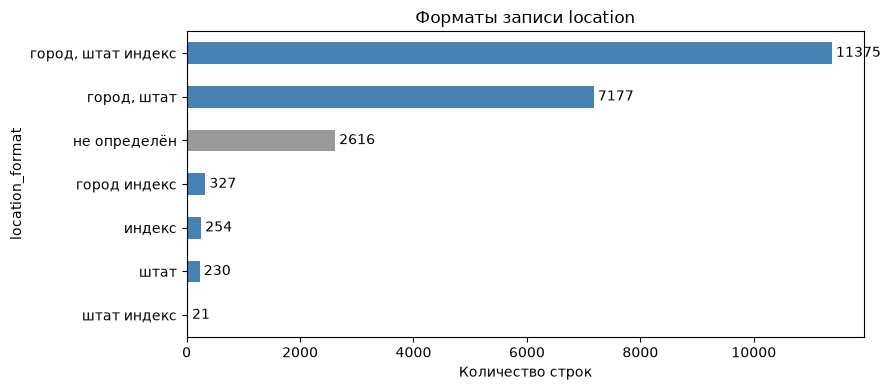

In [8]:
STATES = ("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE "
          "NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC PR").split()

CITY = r"(?P<city>[A-Za-z][A-Za-z .'\-/]*?)"          # название города
STATE = r"(?P<state>" + "|".join(STATES) + r")"         # двухбуквенный код штата
ZIP = r"(?P<zip>\d{5}(?:-\d{4})?)"                     # почтовый индекс 12345 или 12345-6789

LOCATION_FORMATS = {
    "город, штат индекс": rf"^{CITY},?\s+{STATE}\s+{ZIP}$",
    "город, штат":        rf"^{CITY},\s*{STATE}$",
    "штат индекс":        rf"^{STATE}\s+{ZIP}$",
    "город индекс":       rf"^{CITY},?\s+{ZIP}$",
    "штат":               rf"^{STATE}$",
    "индекс":             rf"^{ZIP}$",
}

loc = df["location"].str.strip()
df["location_format"] = "не определён"
for name, pattern in LOCATION_FORMATS.items():
    mask = loc.str.fullmatch(pattern) & (df["location_format"] == "не определён")
    df.loc[mask, "location_format"] = name

fmt_counts = df["location_format"].value_counts()
display(fmt_counts.to_frame("строк"))

ax = fmt_counts.plot.barh(figsize=(9, 4), color=["#999" if i == "не определён" else "steelblue"
                                                 for i in fmt_counts.index])
ax.invert_yaxis()
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlabel("Количество строк")
ax.set_title("Форматы записи location")
plt.tight_layout()
plt.show()

**Выводы.** Чаще всего встречается полный формат `город, штат индекс` (11 375 строк, ≈ 52 %), за ним `город, штат` (7 177, ≈ 33 %). Реже попадаются `город индекс` без штата (327), только индекс (254), только штат (230) и `штат индекс` (21). Формат не удалось определить у 2 616 строк (≈ 12 %). Это строки с одним «городом», который часто вовсе не город (`Contact name ...`, `Multiple locations`), склеенные значения (`DallasTX`), лишние пробелы (`Boston   MA`), адреса и фрагменты описания вакансий.

Одно слово без штата и индекса (`Toronto`, `Project Manager`, `Contact name Justin Kim`) регуляркой нельзя надёжно отличить от города, поэтому формат «только город» я сознательно не выделяю: такие строки уходят в отложенную выборку (задание 1.3).

#### Задание 1.2

В большей части строк удалось извлечь данные из ячейки столбца `location`, но остались и такие, где это не получилось.

1. Вынесите в отдельный датасет записи, в которых не удалось определить формат записи информации о местоположении.
2. Данные о местоположении разделите на 3 столбца: город, код штата, почтовый индекс.

In [9]:
# 1. Отложенный датасет — записи, где формат определить не удалось
unparsed = df[df["location_format"] == "не определён"].copy()
print("Отложено строк:", len(unparsed))

# 2. Разделение location на город / код штата / индекс
#    каждую строку разбираем тем шаблоном, формат которого для неё определён
for col in ["город", "код штата", "почтовый индекс"]:
    df[col] = pd.Series(np.nan, index=df.index, dtype=object)
for name, pattern in LOCATION_FORMATS.items():
    mask = df["location_format"] == name
    ext = loc[mask].str.extract(pattern).rename(
        columns={"city": "город", "state": "код штата", "zip": "почтовый индекс"})
    for col in ext.columns:
        df.loc[mask, col] = ext[col].str.strip()
display(df.loc[df["location_format"] != "не определён",
               ["location", "location_format", "город", "код штата", "почтовый индекс"]].sample(8, random_state=1))
print(df[["город", "код штата", "почтовый индекс"]].notna().sum())

Отложено строк: 2616


,location,location_format,город,код штата,почтовый индекс
18161,"Dallas, TX 75251","город, штат индекс",Dallas,TX,75251
19372,"Parkersburg, WV 26101","город, штат индекс",Parkersburg,WV,26101
12744,"New York City, NY 10023","город, штат индекс",New York City,NY,10023
16881,"Charleston, SC","город, штат",Charleston,SC,NaN
3253,"Parsippany, NJ 07054","город, штат индекс",Parsippany,NJ,07054
6156,"So Burlington, VT 05403","город, штат индекс",So Burlington,VT,05403
16685,"Columbus, OH","город, штат",Columbus,OH,NaN
9518,"Belfast, ME 04915","город, штат индекс",Belfast,ME,04915


город              18879
код штата          18803
почтовый индекс    11977
dtype: int64


#### Задание 1.3

Рассмотрите отложенную часть выборки (ту, где не удалось данные из столбца `location` разделить на три поля) и сделайте выводы о возможности извлечь из данных город, код штата и почтовый индекс. Извлеките все, что возможно. Что невозможно – оставьте пустым.

In [10]:
print("Самые частые значения в отложенной выборке:")
display(unparsed["location"].str.strip().value_counts().head(15))

STATE_NAMES = {s.lower(): s for s in STATES}

def parse_messy_location(text):
    """Пытается достать город, штат и индекс из «грязной» строки location."""
    t = re.sub(r"\s+", " ", str(text)).strip()
    city = state = zip_code = None

    # а) «...City, ST 12345» где-то внутри строки (адреса, «Location: ...»).
    #    Город — от 1 до 4 слов с заглавной буквы прямо перед запятой и кодом штата
    m = re.search(r"([A-Z][A-Za-z.'\-]+(?:\s[A-Z][A-Za-z.'\-]+){0,3}),\s*(?:[A-Za-z]{2},\s*)?("
                  + "|".join(STATES) + r")(?![a-z])\.?\s*(\d{5})?", t)
    if m:
        city, state, zip_code = m.group(1), m.group(2), m.group(3)
        # «...SWCANTON» — город слеплен с адресом: берём хвост из заглавных букв
        glued = re.search(r"[a-z]?([A-Z]{3,})$", city)
        if glued and not city.isupper():
            city = glued.group(1).title()
        # «Dupont RdParkersburg» — город слеплен с улицей: берём часть после склейки
        # (кроме фамильных городов вроде McAllen)
        if re.search(r"[a-z][A-Z][a-z]{3,}$", city) and not re.search(r"\bMa?c[A-Z]", city):
            city = re.split(r"(?<=[a-z])(?=[A-Z][a-z]{3,}$)", city)[-1]
        return city, state, zip_code

    # б) «Boston MA», «DallasTX» — город и штат без запятой или слитно
    m = re.fullmatch(r"([A-Za-z .'\-]+?)\s*(" + "|".join(STATES) + r")", t)
    if m and (t[len(m.group(1)) - 1].islower() or " " in t):
        return m.group(1).strip(), m.group(2), None

    # в) «Latrobe 15650» — город и индекс без запятой
    m = re.fullmatch(r"([A-Za-z .'\-]+?)\s+(\d{5})", t)
    if m:
        return m.group(1), None, m.group(2)

    # г) «Ny, Syracuse» — штат и город в обратном порядке
    m = re.fullmatch(r"([A-Za-z]{2}),\s*([A-Za-z .'\-]+)", t)
    if m and m.group(1).lower() in STATE_NAMES:
        return m.group(2), STATE_NAMES[m.group(1).lower()], None

    # д) Только индекс внутри адреса («Address 40214»)
    m = re.fullmatch(r"Address (\d{5})", t)
    if m:
        return None, None, m.group(1)

    return None, None, None

extracted = unparsed["location"].apply(parse_messy_location).apply(pd.Series)
extracted.columns = ["город", "код штата", "почтовый индекс"]
df.loc[extracted.index, ["город", "код штата", "почтовый индекс"]] = extracted.values

recovered = extracted.notna().any(axis=1)
print(f"Удалось извлечь хотя бы часть адреса: {recovered.sum()} из {len(unparsed)} "
      f"({recovered.mean():.1%})")
display(pd.concat([unparsed.loc[recovered, "location"].str[:70], extracted[recovered]], axis=1).sample(10, random_state=3))
print("Не удалось извлечь ничего, примеры:")
display(unparsed.loc[~recovered, "location"].str[:80].value_counts().head(10))

Самые частые значения в отложенной выборке:


location
Location:                                             137
Multiple locations                                     23
Owning your own business has never been this easy!     22
DallasTX                                               19
Position Information                                   18
BostonMA                                               15
84 Lumber                                              15
ChicagoIL                                              11
AtlantaGA                                              11
Home Based                                             10
Contact name Lisa van Horne                             9
Full Time Employee                                      9
Contact name Justin Kim                                 8
Job location not provided                               8
Contact name Daniel Nadruz                              8
Name: count, dtype: int64

Удалось извлечь хотя бы часть адреса: 1079 из 2616 (41.2%)


,location,город,код штата,почтовый индекс
1272,"Job Title: Security Systems EngineerJob Location: Herndon, VA.Job Code",Herndon,VA,None
5018,ColumbusOH,Columbus,OH,None
16353,"Phone 813-336-6355 Address 3980 Tampa Rd Suite 205Oldsmar, FL 34677",Oldsmar,FL,34677
10477,Role: Automation(UFT) test engineer Full time onlyLocation: San Antoni,San Antonio,TX,None
20838,"Location: Carmel, IN (Service Center Operations - Central)Are you look",Carmel,IN,None
2138,Job Description Job #: 671391Role: Hadoop AdministratorIndustry: Oil,Houston,TX,None
6815,"Title - Java/ Python DeveloperLocation -Middle Town, NJDuration - 6+ M",Middle Town,NJ,None
20968,"Address 1525 Dupont RdParkersburg, WV 26101",Parkersburg,WV,26101
1857,Job Area: Information Security ConsultingTitle: Senior Consultant (Int,SDN,IA,None
5439,Job ID 2016-1035 Job Locations US-NJ-Paramus Posted Date 3/10/2016,Washington,DC,None


Не удалось извлечь ничего, примеры:


location
Location:                                                                           133
Job Description : Want more than just a job? Join Forever 21’s Retail Operations     28
Multiple locations                                                                   23
Owning your own business has never been this easy!                                   22
When you choose Toll Brothers, you enjoy all the special advantages offered by "     19
Position Information                                                                 18
84 Lumber                                                                            15
Home Based                                                                           10
Full Time Employee                                                                    9
Contact name Lisa van Horne                                                           9
Name: count, dtype: int64

**Выводы.** В отложенной выборке есть несколько типов записей.
- **Восстанавливаемые.** Город и штат склеены (`DallasTX`) или разделены пробелами без запятой (`Boston   MA`). Город указан с индексом без запятой (`Latrobe 15650`). Порядок обратный (`Ny, Syracuse`). Город, штат и индекс спрятаны внутри адреса или текста (`Address ...Knoxville, TN 37912`, `...Location: Dallas/Fort Worth, TX...`). Из них данные извлекаются регулярками.
- **Невосстанавливаемые из `location`.** Контакты (`Contact name ...`, `Phone ...`), названия компаний и должностей, `Multiple locations`, `Home Based`, `Telecommute`, обрывки описаний. Местоположения тут просто нет, поэтому поля остаются пустыми. Частично их можно было бы заполнить из `job_title` (`... Job in Madison`) или `page_url`, где обычно есть город и штат; это как раз одно из дополнительных заданий.

### Задание 2

В задании 2 необходимо провести обработку столбца `salary`.

#### Задание 2.1

В столбце `salary`, как и в `location`, данные не стандатизированы. В нем в основном можно встретить записи в следующих форматах:

* 10.00 - 20.00 &dollar; &sol;hour
* 10,000.00 - 20,000.00 &dollar; &sol;year
* &dollar;10.00 &sol;hour
* &dollar;10,000.00+ &sol;year
* Up to &dollar;20,000.00

Основные проблемы, которые стоит учесть при обработке форматов:
- В каждом из форматов может быть или не быть знака доллара.
- Может отсутствовать информация о периоде, за который указывается зарплата (`/hour` или `/year` в примерах).
- Зарплата может быть указана за месяц (`/month`) и за неделю (`/week`).
- В начале, конце и середине некоторых строк есть лишние пробелы, которые не стоит учитывать.

**Задание:**
1. Определите весь перечень встречающихся форматов и напишите одно или несколько регулярных выражений для их поиска.
2. Покажите на столбчатой диаграмме количество записей, содержащих каждый из форматов. Сделайте выводы.

,строк
salary_format,
"диапазон «a - b», с периодом",2751
текст / не распознано,406
"от «a+», с периодом",172
"до «Up to a», без периода",101
"диапазон «a - b», без периода",10
"одно число «a», без периода",6


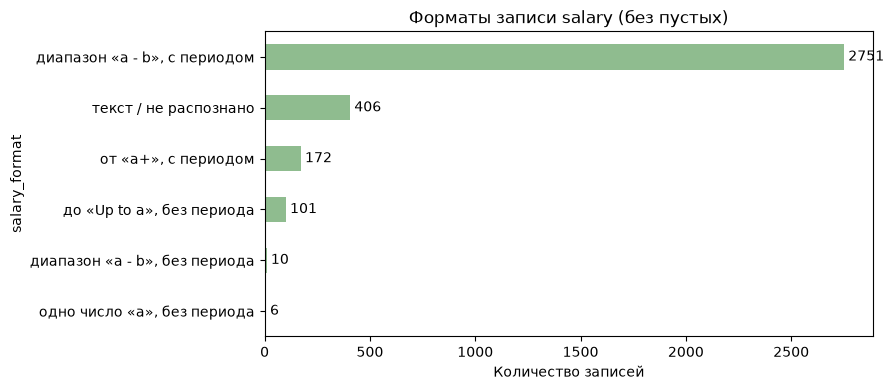

Примеры нераспознанного текста:


salary
Commensurate with Experience                                       38
DOE                                                                12
Competitive                                                        11
W-2, Weekly Paycheck, Great Compensation Package and Incentives    10
Based on experience                                                10
BOE                                                                 7
Based on Experience                                                 7
Salary commensurate with experience                                 5
Name: count, dtype: int64

In [11]:
NUM = r"\$?\s*(?P<{}>\d[\d,]*(?:\.\d+)?)"
PERIOD = r"\s*\$?\s*(?:/\s*(?:per\s+)?(?P<period>hour|year|month|week|day))?"

SALARY_FORMATS = {
    "диапазон «a - b»":   rf"^{NUM.format('min')}\s*-\s*{NUM.format('max')}{PERIOD}",
    "от «a+»":            rf"^{NUM.format('min')}\s*\+{PERIOD}",
    "до «Up to a»":       rf"^[Uu]p\s+to\s+{NUM.format('min')}{PERIOD}",
    "одно число «a»":     rf"^{NUM.format('min')}{PERIOD}\s*$",
}

sal = df["salary"].str.strip()
df["salary_format"] = np.where(sal.isna(), "пусто", "текст / не распознано")
for name, pattern in SALARY_FORMATS.items():
    mask = sal.str.match(pattern, flags=re.I, na=False) & (df["salary_format"] == "текст / не распознано")
    df.loc[mask, "salary_format"] = name

# Отдельно отмечаем, указан ли период
has_period = sal.str.contains(r"/\s*(?:per\s+)?(?:hour|year|month|week|day)", case=False, na=False)
parsed = ~df["salary_format"].isin(["пусто", "текст / не распознано"])
df.loc[parsed, "salary_format"] += np.where(has_period[parsed], ", с периодом", ", без периода")

sal_counts = df.loc[df["salary_format"] != "пусто", "salary_format"].value_counts()
display(sal_counts.to_frame("строк"))

ax = sal_counts.plot.barh(figsize=(9, 4), color="darkseagreen")
ax.invert_yaxis()
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlabel("Количество записей")
ax.set_title("Форматы записи salary (без пустых)")
plt.tight_layout()
plt.show()

print("Примеры нераспознанного текста:")
display(sal[df["salary_format"] == "текст / не распознано"].value_counts().head(8))

**Выводы.** Из 3 446 непустых значений 2 761 (≈ 80 %) записаны диапазоном `a - b $ /период`. Остальные форматы встречаются редко: «от» (`$a+ /year`), «до» (`Up to $a`, почти всегда без периода) и одно число. Примерно 11 % записей — просто текст (`Commensurate with experience`, `DOE`, `Competitive`, перечень льгот), суммы в них нет. Часть диапазонов дополнена текстом прямо после периода (`/yearBonus`): регулярка берёт числа и период, а хвост отбрасывает. Записей с суммой, но без периода, немного — около 120 (≈ 4 % распознанных); их обработаем в задании 2.3.

#### Задание 2.2

1. Разделите столбец `salary` зарплаты три: `минимальная граница зарплаты`, `максимальная граница зарплаты`, `период`. Если значение суммы указано только одно, считайте, что это минимальная зарплата. Значение суммы в обоих столбцах преобразуйте в формат `float`.
2. Покажите на столбчатой диаграмме с группировкой среднюю и медианную минимальную зарплату в каждом периоде. Сделайте выводы.

,salary,минимальная граница зарплаты,максимальная граница зарплаты,период
21220,"60,000.00 - 70,000.00 $ /year",60000.0,70000.0,year
10515,38.00 - 42.50 $ /hour,38.0,42.5,hour
19726,"33,000.00 - 35,000.00 $ /year",33000.0,35000.0,year
5299,20.00 - 23.00 $ /hour,20.0,23.0,hour
5073,"80,000.00 - 100,000.00 $ /year+ Bonus",80000.0,100000.0,year
17010,"40,000.00 - 100,000.00 $ /year",40000.0,100000.0,year
12567,40.00 - 48.00 $ /hour,40.0,48.0,hour
15017,"90,000.00 - 100,000.00 $ /year",90000.0,100000.0,year


минимальная граница зарплаты     float64
максимальная граница зарплаты    float64
период                            object
dtype: object
период
NaN      19078
year      1755
hour      1142
month       17
week         6
Name: count, dtype: int64


,среднее,медиана,записей
период,,,
hour,187.61,15.13,1142
day,525.00,525.00,2
week,593.67,600.00,6
month,6048.41,4905.22,17
year,59789.88,55000.00,1755


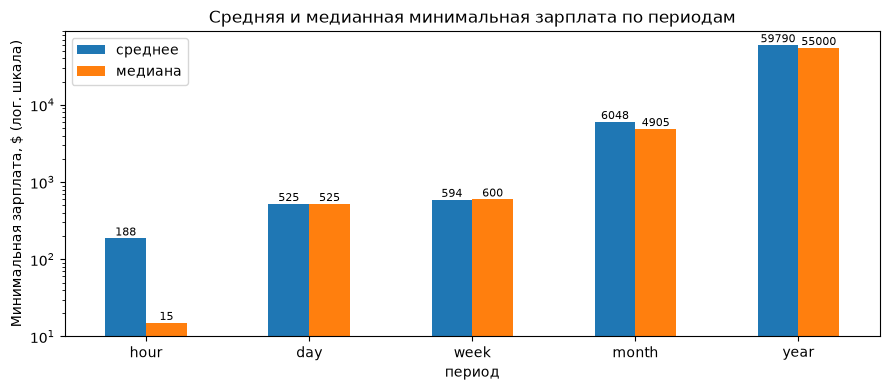

In [12]:
def to_float(s):
    return pd.to_numeric(s.str.replace(",", "", regex=False), errors="coerce")

df["минимальная граница зарплаты"] = np.nan
df["максимальная граница зарплаты"] = np.nan
df["период"] = pd.Series(np.nan, index=df.index, dtype=object)

for pattern in SALARY_FORMATS.values():
    ext = sal.str.extract(pattern, flags=re.I)
    target = df["минимальная граница зарплаты"].isna() & ext["min"].notna()
    df.loc[target, "минимальная граница зарплаты"] = to_float(ext.loc[target, "min"])
    if "max" in ext:
        df.loc[target, "максимальная граница зарплаты"] = to_float(ext.loc[target, "max"])
    df.loc[target, "период"] = ext.loc[target, "period"].str.lower().astype(object)

salary_cols = ["salary", "минимальная граница зарплаты", "максимальная граница зарплаты", "период"]
display(df.loc[df["минимальная граница зарплаты"].notna(), salary_cols].sample(8, random_state=7))
print(df[salary_cols[1:]].dtypes)
print(df["период"].value_counts(dropna=False).head())

stats = (df.dropna(subset=["период"])
           .groupby("период")["минимальная граница зарплаты"]
           .agg(среднее="mean", медиана="median", записей="count")
           .reindex(["hour", "day", "week", "month", "year"]).dropna())
display(stats.round(2))

ax = stats[["среднее", "медиана"]].plot.bar(figsize=(9, 4), logy=True, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8)
ax.set_ylabel("Минимальная зарплата, $ (лог. шкала)")
ax.set_title("Средняя и медианная минимальная зарплата по периодам")
plt.tight_layout()
plt.show()

**Выводы.** Суммы за разные периоды отличаются на порядки: около 15–20 $/час, тысячи в месяц, десятки тысяч в год. Поэтому график построен в логарифмической шкале. В каждом периоде среднее заметно выше медианы, то есть внутри есть выбросы: очень большие суммы, ошибки ввода вроде «9.00 - 900.00 $/hour», годовые суммы, помеченные как часовые. Для сравнения периодов надёжнее медиана. Сравнивать суммы между периодами без приведения к одной шкале (например, к году) нельзя. Периоды `week` и `day` представлены единичными записями, статистика по ним ненадёжна.

#### Задание 2.3

Как было отмечено в задании 2.1, период, за который указывается зарплата, может отсутствовать. Восполните этот пробел в данных следующим образом:

1. Определите диапазон изменения (разброс) значений денежной суммы за каждый из встречающихся в данных периодов. Постройте гистограмму для каждого периода. Сопоставьте результаты с результатами в задании 2.2.
2. Определите, к среднему значению за какой период ближе всего сумма, у которой период не указан. Укажите для найденный период. В спорных случаях, где сумма одинаково близка к нескольким диапазонам, не выбирайте ничего. Учтите, что в данных могут быть выбросы.

,count,mean,std,min,25%,50%,75%,max
период,,,,,,,,
hour,1142.0,187.61,3575.22,0.0,12.0,15.13,23.0,100000.00
day,2.0,525.00,530.33,150.0,337.5,525.00,712.5,900.00
week,6.0,593.67,419.05,12.0,337.5,600.00,900.0,1100.00
month,17.0,6048.41,4607.15,1800.0,3674.0,4905.22,6000.0,17688.94
year,1755.0,59789.88,52169.88,0.0,40000.0,55000.00,75000.0,1000000.00


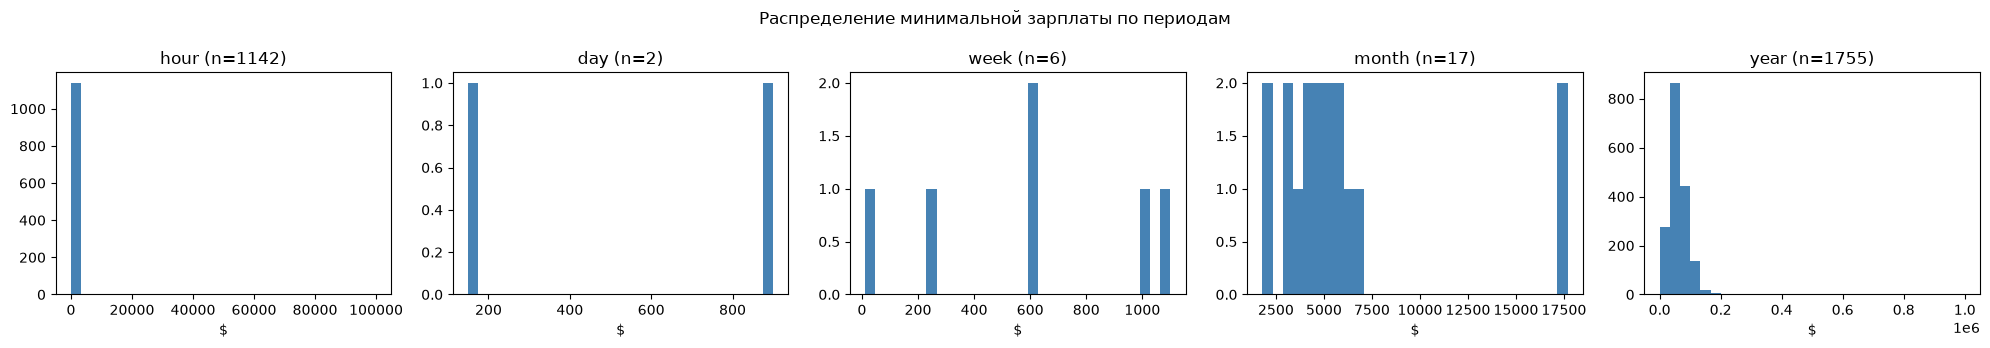

Среднее без выбросов по периодам:


,центр
период,
hour,16.16
day,525.00
week,593.67
month,4496.34
year,55691.68


Записей без периода: 118, период восстановлен: 112, оставлено пустым (спорные): 6


,восстановлено
минимальная граница зарплаты,
hour,67
year,44
month,1


,salary,минимальная граница зарплаты,период
4251,Up to $60000.00,60000.0,year
12107,Up to $18.00,18.0,hour
5362,Up to $55000.00,55000.0,year
7623,Up to $15.00,15.0,hour
2424,"108,887.00 - 141,555.00",108887.0,year
7573,Up to $15.00,15.0,hour
7412,Up to $54000.00,54000.0,year
9331,Up to $14.00,14.0,hour
7742,Up to $14.00,14.0,hour
5413,Up to $60000.00,60000.0,year


In [13]:
known = df.dropna(subset=["период", "минимальная граница зарплаты"])
periods = [p for p in ["hour", "day", "week", "month", "year"] if p in known["период"].unique()]

# 1. Разброс и гистограммы по каждому периоду
spread = known.groupby("период")["минимальная граница зарплаты"].describe().reindex(periods)
display(spread.round(2))

fig, axes = plt.subplots(1, len(periods), figsize=(4 * len(periods), 3.5))
for ax, p in zip(np.atleast_1d(axes), periods):
    vals = known.loc[known["период"] == p, "минимальная граница зарплаты"]
    ax.hist(vals, bins=30, color="steelblue")
    ax.set_title(f"{p} (n={len(vals)})")
    ax.set_xlabel("$")
plt.suptitle("Распределение минимальной зарплаты по периодам")
plt.tight_layout()
plt.show()

# 2. Робастное «типичное» значение каждого периода: среднее после удаления выбросов по IQR
def iqr_mean(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return s[(s >= q1 - 1.5 * iqr) & (s <= q3 + 1.5 * iqr)].mean()

centers = known.groupby("период")["минимальная граница зарплаты"].apply(iqr_mean).reindex(periods)
print("Среднее без выбросов по периодам:")
display(centers.round(2).to_frame("центр"))

AMBIGUITY = 0.10  # если две ближайшие середины почти равноудалены (разница < 10%) — период не выбираем

def guess_period(value):
    dist = (centers - value).abs().sort_values()
    best, second = dist.iloc[0], dist.iloc[1]
    if second - best < AMBIGUITY * second:
        return np.nan
    return dist.index[0]

no_period = df["минимальная граница зарплаты"].notna() & df["период"].isna()
df["период восстановлен"] = False
guessed = df.loc[no_period, "минимальная граница зарплаты"].apply(guess_period)
df.loc[no_period, "период"] = guessed
df.loc[no_period & df["период"].notna(), "период восстановлен"] = True

print(f"Записей без периода: {no_period.sum()}, период восстановлен: {guessed.notna().sum()}, "
      f"оставлено пустым (спорные): {guessed.isna().sum()}")
display(guessed.value_counts().to_frame("восстановлено"))
display(df.loc[no_period, ["salary", "минимальная граница зарплаты", "период"]].sample(10, random_state=2))

**Выводы.** Распределения по периодам почти не пересекаются: часовые ставки лежат в пределах десятков долларов, месячные — тысяч, годовые — десятков тысяч. Есть и выбросы (например, годовые суммы с пометкой `/hour`). Поэтому «центр» периода считается как среднее **после удаления выбросов по IQR**, а не обычное среднее, которое выбросы тянут вверх (это видно и по графику из 2.2). Записи без периода получают период, к центру которого их сумма ближе всего. Небольшие суммы (`Up to $15.00`, `8.00`) становятся часовыми, `Up to $45000.00` — годовыми. Если сумма почти одинаково близка к двум центрам (разница расстояний меньше 10 %), период остаётся пустым, как требует задание.

### Задание 3

В задании 3 необходимо провести обработку столбца `job_type`. Выясните, какие форматы значений есть в столбце `job_type`. Сделайте выводы. При необходимости – стройте графики.

Уникальных значений: 39


,строк
job_type,
Full Time,6757
Full Time Employee,6617
"Full Time, Employee",3360
NaN,1628
Full Time Temporary/Contract/Project,1062
"Full Time, Temporary/Contract/Project",533
"Full Time , Employee",406
Part Time Employee,382
Part Time,329


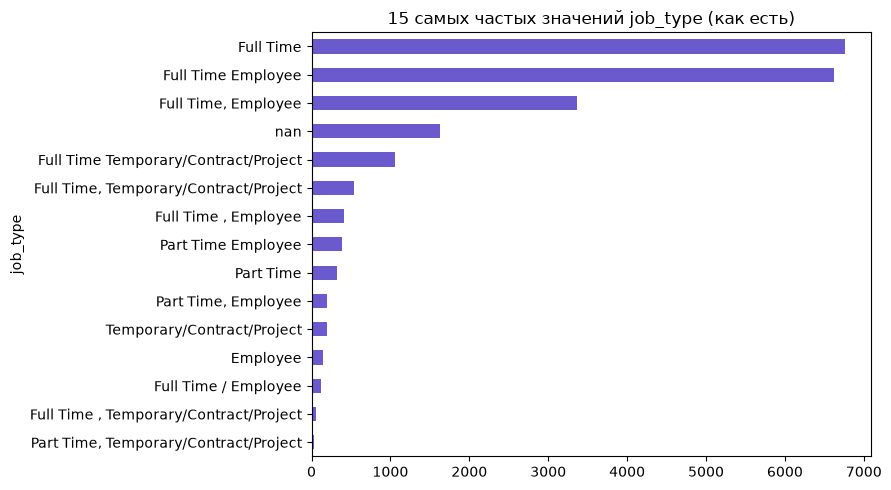

In [14]:
jt_counts = df["job_type"].value_counts(dropna=False)
print("Уникальных значений:", df["job_type"].nunique())
display(jt_counts.to_frame("строк"))

ax = jt_counts.head(15).plot.barh(figsize=(9, 5), color="slateblue")
ax.invert_yaxis()
ax.set_title("15 самых частых значений job_type (как есть)")
plt.tight_layout()
plt.show()

**Выводы.** В столбце 39 разных значений, хотя смысловых комбинаций гораздо меньше. Один и тот же тип пишут с разными разделителями (`Full Time Employee`, `Full Time, Employee`, `Full Time , Employee`, `Full Time / Employee`, `Full Time/ Employee`), с двойными и концевыми пробелами, с префиксом `Job Type`, встречается мусор `/ >`. В 1 628 строках значения нет, иногда указана только одна часть (`Full Time`, `Employee`). Есть и выбивающиеся значения: `Exempt`, `Seasonal`.

Вы заметили, что многие значения фактически одинаковые, но немного по-разному отформатированы? Приведем их к единому формату.

In [15]:
def normalize_job_type(value):
    if pd.isna(value):
        return np.nan
    v = re.sub(r"^\s*Job Type\s*", "", value, flags=re.I)                   # убираем префикс «Job Type»
    v = v.replace("Temporary/Contract/Project", "Temporary-Contract-Project")  # защищаем «/» внутри типа
    v = re.sub(r"\s*[,/>]+\s*", " ", v)                                        # разделители , / > → пробел
    v = re.sub(r"\s+", " ", v).strip()                                         # лишние пробелы
    return v.replace("Temporary-Contract-Project", "Temporary/Contract/Project")

df["job_type_clean"] = df["job_type"].apply(normalize_job_type)
print("Уникальных значений: было", df["job_type"].nunique(), "→ стало", df["job_type_clean"].nunique())
display(df["job_type_clean"].value_counts(dropna=False).to_frame("строк"))

Уникальных значений: было 39 → стало 15


,строк
job_type_clean,
Full Time Employee,10538
Full Time,6773
Full Time Temporary/Contract/Project,1654
NaN,1628
Part Time Employee,586
Part Time,330
Temporary/Contract/Project,193
Employee,148
Part Time Temporary/Contract/Project,57


Столбец `job_type` состоит из двух частей: "полнота" занятости (`Full Time`, `Part Time`, `Per Diem`) и "тип" занятости (`Employee`, `Intern`). Кроме того, встречаются и неполные записи.

Задание:
1. Написать одно или несколько регулярных выражений для разделения столбца `job_type` на два: `полнота занятости`, `тип занятости`.
2. Если данные о полноте отсутствуют, внесите значение `Full Time`.
Если отсутствуют данные о типе – внесите `Employee`.
3. Постройте столбчатую диаграмму со стековой группировкой для полноты и типа занятости. Сделайте выводы.

Значения, не подошедшие под шаблон (заполнены по умолчанию): ['Exempt']


,job_type,полнота занятости,тип занятости
0,Full Time Employee,Full Time,Employee
1,Full Time,Full Time,Employee
2,"Full Time, Employee",Full Time,Employee
8,Part Time Employee,Part Time,Employee
9,NaN,Full Time,Employee
21,Full Time Temporary/Contract/Project,Full Time,Temporary/Contract/Project
82,"Full Time , Employee",Full Time,Employee
90,"Full Time, Temporary/Contract/Project",Full Time,Temporary/Contract/Project
129,Employee,Full Time,Employee
136,Part Time,Part Time,Employee


тип занятости,Employee,Intern,Seasonal,Temporary/Contract/Project
полнота занятости,,,,
Full Time,19088,5,0,1847
Part Time,916,3,17,57
Per Diem,63,0,0,4


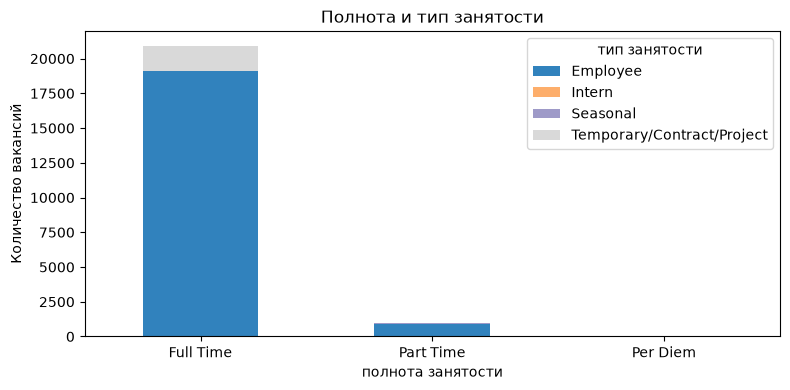

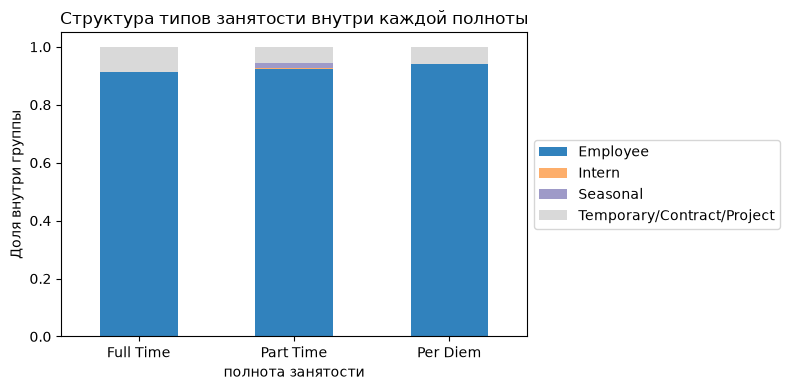

In [16]:
FULLNESS = r"(?P<fullness>Full Time|Part Time|Per Diem)"
KIND = r"(?P<kind>Employee|Intern|Temporary/Contract/Project|Seasonal)"
JOB_TYPE_RE = rf"^(?:{FULLNESS})?\s*(?:{KIND})?$"

parts = df["job_type_clean"].str.extract(JOB_TYPE_RE)
df["полнота занятости"] = parts["fullness"].fillna("Full Time")
df["тип занятости"] = parts["kind"].fillna("Employee")

unmatched = df["job_type_clean"].notna() & parts.isna().all(axis=1)
print("Значения, не подошедшие под шаблон (заполнены по умолчанию):",
      df.loc[unmatched, "job_type_clean"].unique())

display(df[["job_type", "полнота занятости", "тип занятости"]].drop_duplicates().head(12))

ct = pd.crosstab(df["полнота занятости"], df["тип занятости"])
display(ct)

ax = ct.plot.bar(stacked=True, figsize=(8, 4), rot=0, colormap="tab20c")
ax.set_ylabel("Количество вакансий")
ax.set_title("Полнота и тип занятости")
plt.tight_layout()
plt.show()

ax = ct.div(ct.sum(axis=1), axis=0).plot.bar(stacked=True, figsize=(8, 4), rot=0, colormap="tab20c")
ax.set_ylabel("Доля внутри группы")
ax.set_title("Структура типов занятости внутри каждой полноты")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

**Выводы.** После нормализации в столбце остаётся 15 вариантов вместо 39. Разбор на две части показывает, что абсолютное большинство вакансий (≈ 95 %) — полная занятость, и почти все они — штатные позиции (`Employee`). Вторая по величине группа — временная или проектная работа (`Temporary/Contract/Project`), заметная и в полной, и в частичной занятости. Частичная занятость и `Per Diem` встречаются редко, стажировок единицы. Учтите, что `Full Time` и `Employee` здесь отчасти завышены: по условию ими заполнены пропуски (1 628 пустых строк и неполные записи), то есть это значение по умолчанию, а не данные.

# Порядок защиты работы

**Для защиты работы необходимо:**
1. Предоставить результаты выполнения всех заданий в виде ссылки на Google Colab в новой ветке своего репозитория по первой лабораторной на GitHub. Открыть `pull request`.
2. Выполнить дополнительное задание в процессе сдачи работы. Дополнительное задание представляет собой решение задачи на обработку данных лабораторной работы, меньшее по объему, но сопоставимое по сложности тем заданиям, которые требовалось выполнить в рамках работы.

**Примеры дополнительных заданий:**
1. В столбце `sector` часто представлены данные из столбца `organization` и наоборот. Устраните эту проблему.
2. В столбце `job_title` часто можно частично или полностью встретить указание местоположения организации. Сравните, совпадают ли в таких случаях данные с тем, что указано в столбцах `город`, `код штата`, `почтовый индекс`. Если в этих трех столбцах данные отсутствуют, заполните их данными из столбца `job_title`.
3. Практически во всех столбцах датасета вместо соответствующих названию данных иногда встречается текст из `job_description`. Найдите такие столбцы и записи с описанием вакансии в них. Покажите на столбчатой диаграмме, в каких столбцах и в каком количестве находится информация из столбца `job_description`.

# Дополнительные материалы

1. DAMA-DMBOK: Свод знаний по управлению данными: Второе издание / DAMA International; [пер. с англ.]. – Москва: ООО "Олимп-Бизнес", 2021. – 828 с.
2. Макгрегор, С. Обработка данных на Python: Data Wrangling и Data Quality: [Текст] / С. Макгрегор. – Москва: БХВ, 2024. – 432 с.